In [1]:
# Use the `docking_env` conda environment to run this notebook
import docking_utils
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymol2
from IPython.display import Image, display
from rdkit import Chem

# File paths

In [2]:
# Example docking results
docking_results_path: str = "./example_output/test_set/VINA_redocked_FH_id=1_exhaust=32_numModes=100_eRange=20.csv"

# Example system
example_system_path: str = "./example_output/2pjc__3__1.C__1.H_1.I"
system_path: str = (
    f"{example_system_path}/receptor_merged_1.I.pdbqt"  # The receptor used for docking
)
crystal_path: str = (
    f"{example_system_path}/1.I.sdf"  # The crystal structure of the ligand
)
docked_vina_path: str = f"{example_system_path}/VINA_redocked_FH_id=1_exhaust=32_numModes=100_eRange=20_lig=1.I.sdf"  # The docked ligand structure with all 100 poses

# Utils

In [3]:
def calculate_success_rate(
    df: pd.DataFrame,
    unique_identifier: str = "system_id__ligand_id",
    sr_col: str = "rmsd",
    top_n_poses: list[int] | None = None,
) -> list[float]:
    """
    Calculate success rates for different top-N poses.

    For each unique system, find the minimum ranking (i.e. pose number) among the poses with rmsd < 2.
    A system is counted as a "success" for Top-N if its best pose (lowest rank) has an rmsd < 2.

    Parameters
    ----------
    df : pd.DataFrame
        DataFrame containing the docking results.
    unique_identifier : str
        Column name for unique system identifiers.
    sr_col : str
        Column name for RMSD values.
    top_n_poses : list[int], optional
        List of top-N poses to evaluate. Defaults to [1, 3, 5, 10, 20, 30, 50, 100].

    Returns
    -------
    list[float]
        List of success rates for each top-N pose.
    """
    if top_n_poses is None:
        top_n_poses = [1, 3, 5, 10, 20, 30, 50, 100]

    print(f"N_samples = {df[unique_identifier].nunique()}")

    # For each system, find the minimum "pose" value among rows where rmsd < 2.
    min_poses = df.groupby(unique_identifier).apply(
        lambda group: (
            group.loc[group[sr_col] <= 2, "pose"].min()
            if not group.loc[group[sr_col] <= 2].empty
            else np.inf
        )
    )
    # For each top-N threshold, compute the fraction of systems that succeed.
    success_rates = [(min_poses <= n).mean() for n in top_n_poses]
    return success_rates

# Visualise system with PyMOL

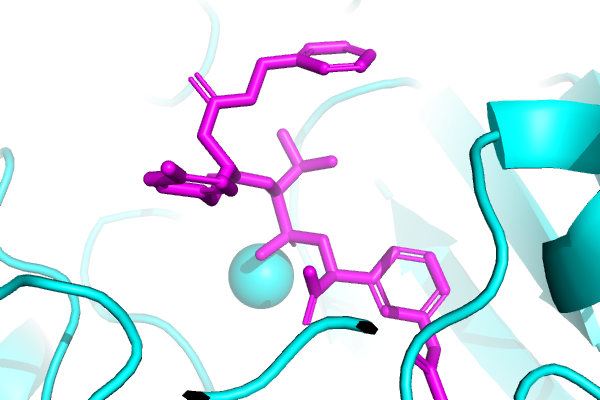

In [4]:
# Start PyMOL in headless mode
with pymol2.PyMOL() as pymol:
    pymol.cmd.load(system_path, "receptor")
    pymol.cmd.load(crystal_path, "ligand")
    pymol.cmd.zoom("ligand")

    pymol.cmd.color("cyan", "receptor")
    pymol.cmd.color("magenta", "ligand")

    pymol.cmd.png(
        f"{example_system_path}/ligand_focus.png", width=600, height=400, ray=1
    )
    display(Image(filename=f"{example_system_path}/ligand_focus.png"))

## RMSD and MBG RMSD

In [5]:
# Parse the docked Vina results
docked_mols, free_energies, rmsds = docking_utils.get_docked_mols(
    docked_vina_path, crystal_path, "vina"
)

# Metal positions
# These can be taken from the metal_ligand_data.json generated during the data curation step
metals_2pjc = [["Zn", [-2.339, 40.483, 132.424]]]
metal_coords = [m[1] for m in metals_2pjc]

## Uncomment to load metal coordinates from metal_ligand_data.json
# metal_ligand_data_path = f"path/to/metal_ligand_data.json"
# with open(metal_ligand_data_path, "r") as f:
#     metal_ligand_data = json.load(f)
# system_id = "2pjc__3__1.C__1.H_1.I"
# metals = metal_ligand_data[system_id]["metals"]
# metal_coords = [m[1] for m in metals]

# Load the crystal ligand and remove hydrogens
crystal_ligand = Chem.SDMolSupplier(crystal_path)[0]
crystal_ligand = Chem.RemoveHs(crystal_ligand)

MBG_35_rmsds = []

for docked_mol in docked_mols:
    symm_rmsd: float
    best_isomorphism: tuple[list[int], list[int]]

    # Calculate the symmetry-corrected RMSD and best isomorphism
    symm_rmsd, best_isomorphism = docking_utils.calculate_symmetry_corrected_rmsd(
        crystal_path, docked_mol
    )
    # Calculate the MBG RMSD
    close_rmsd_35 = docking_utils.get_rmsd_within_metal_radius(
        crystal_ligand, docked_mol, best_isomorphism, metal_coords, dist_threshold=3.5
    )

    MBG_35_rmsds.append(close_rmsd_35)

In [6]:
# Pose numbers (1 to the number of docked poses)
poses = range(1, len(rmsds) + 1)

# Create scatter plot
plt.figure(figsize=(10, 6))
plt.scatter(poses, MBG_35_rmsds, label="MBG RMSD", alpha=0.6)
plt.scatter(poses, rmsds, label="RMSD", alpha=0.6)

# Add horizontal line at RMSD = 2Å
plt.axhline(y=2, color="r", linestyle="--", alpha=0.3)

# Customize plot
plt.xlabel("Pose Number")
plt.ylabel("RMSD (Å)")
plt.title("RMSD vs MBG RMSD for docked VINA example system")
plt.legend()
plt.grid(True, alpha=0.3)

# Show plot
plt.show()

# Docking results

In [7]:
# Load docking results
docking_results: pd.DataFrame = pd.read_csv(docking_results_path)
docking_results["system_id__ligand_id"] = (
    docking_results["system_id"] + "__" + docking_results["ligand_id"]
)
docking_results.head(5)

,pose,rmsd,symm_rmsd,free_energy,intermolecular_energy,internal_energy,system_id,ligand_id,system_id__ligand_id
0,1,3.879082,3.879082,-5.288,-9.152,-1.856,4m18__2__1.F__1.OA_1.R,1.R,4m18__2__1.F__1.OA_1.R__1.R
1,2,1.898498,1.898498,-5.244,-9.302,-1.629,4m18__2__1.F__1.OA_1.R,1.R,4m18__2__1.F__1.OA_1.R__1.R
2,3,3.219320,3.219320,-5.153,-9.144,-1.630,4m18__2__1.F__1.OA_1.R,1.R,4m18__2__1.F__1.OA_1.R__1.R
3,4,4.279571,4.279571,-5.105,-8.976,-1.715,4m18__2__1.F__1.OA_1.R,1.R,4m18__2__1.F__1.OA_1.R__1.R
4,5,6.058912,6.058912,-5.087,-9.046,-1.614,4m18__2__1.F__1.OA_1.R,1.R,4m18__2__1.F__1.OA_1.R__1.R


In [8]:
# Calculate success rates
top_n_poses = [1, 3, 5, 10, 20, 30, 50, 100]
success_rates = calculate_success_rate(docking_results)

# Create bar plot
plt.figure(figsize=(10, 6))
plt.bar(range(len(top_n_poses)), success_rates, alpha=0.6)
plt.xticks(range(len(top_n_poses)), [f"Top-{n}" for n in top_n_poses])

# Customize plot
plt.xlabel("Number of Poses")
plt.ylabel("Success Rate")
plt.title("Success Rate vs Number of Top Poses")
plt.grid(True, alpha=0.3)

# Add value labels on top of bars
for i, v in enumerate(success_rates):
    plt.text(i, v + 0.01, f"{v:.2%}", ha="center")

plt.show()

N_samples = 145
